In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from utils import *
import pickle
from sklearn.metrics import roc_auc_score, roc_curve
from concurrent.futures import ThreadPoolExecutor, as_completed

In [2]:
train_feats = pd.read_csv('../Data/train_features.csv')
features_dict = pickle.load(open('../Files/all_features.pkl', 'rb'))
all_feats = sum(features_dict.values(), [])

### Firm size

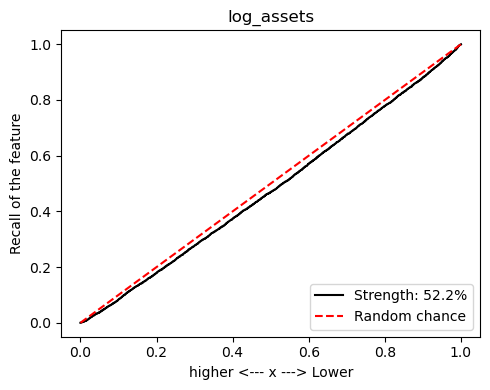

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
0,log_assets,0.521772,0.478228,Decreases with feature


In [3]:
asset_features = ['log_assets']
asset_feature_directions = visualize_multiple_features(train_feats, asset_features, cols=1)
asset_feature_directions

### Profitability

In [10]:
train_feats['roe'].min(), train_feats['roe'].max()

(-inf, inf)

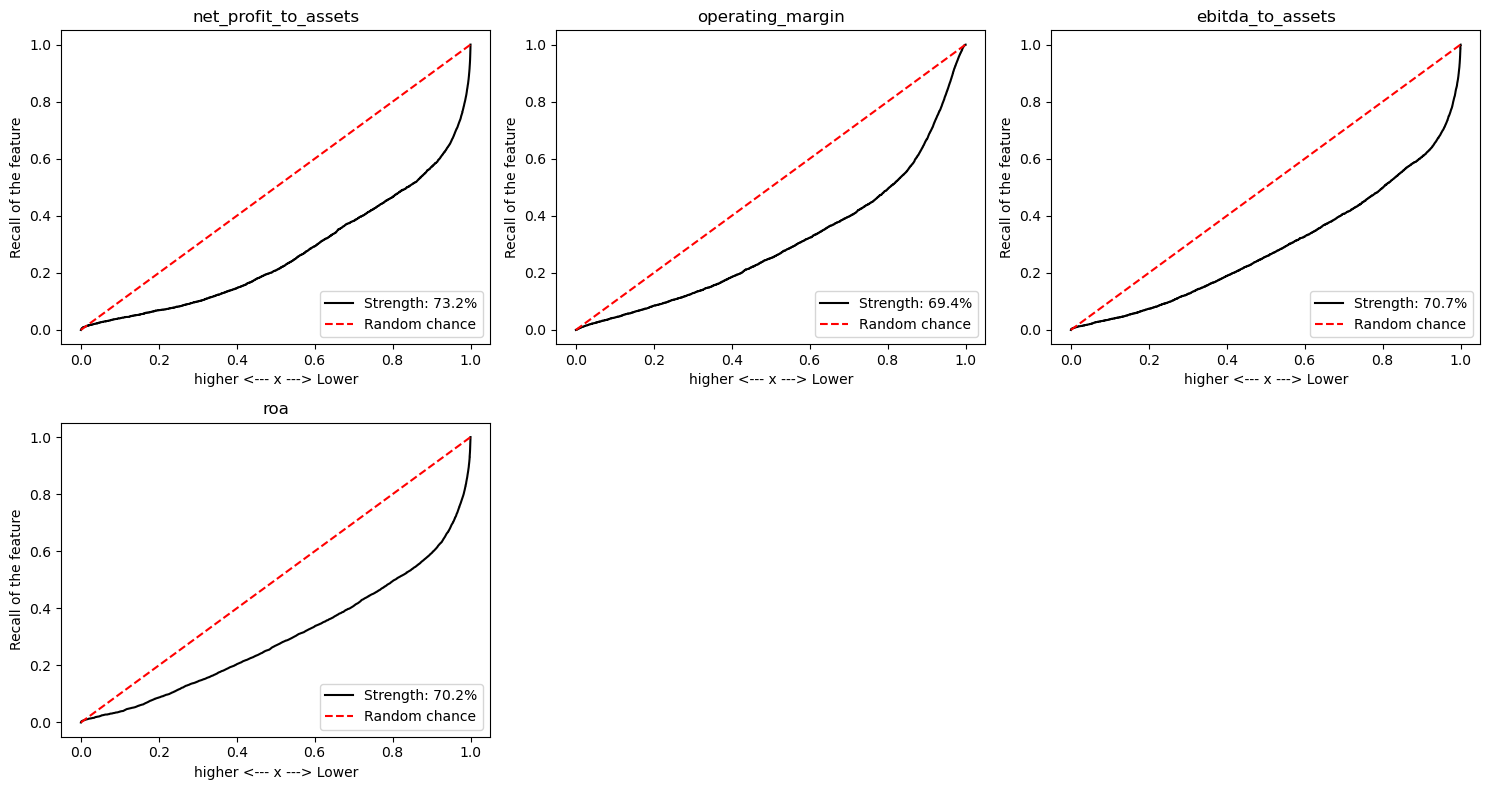

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
0,net_profit_to_assets,0.732304,0.267696,Decreases with feature
2,ebitda_to_assets,0.707151,0.292849,Decreases with feature
3,roa,0.701883,0.298117,Decreases with feature
1,operating_margin,0.694305,0.305695,Decreases with feature


In [11]:
profitability = ["net_profit_to_assets", "operating_margin", "ebitda_to_assets", "roa"]#, "roe"]
profitability_directions = visualize_multiple_features(train_feats, profitability, cols=3)
profitability_directions

### Liquidity and WC

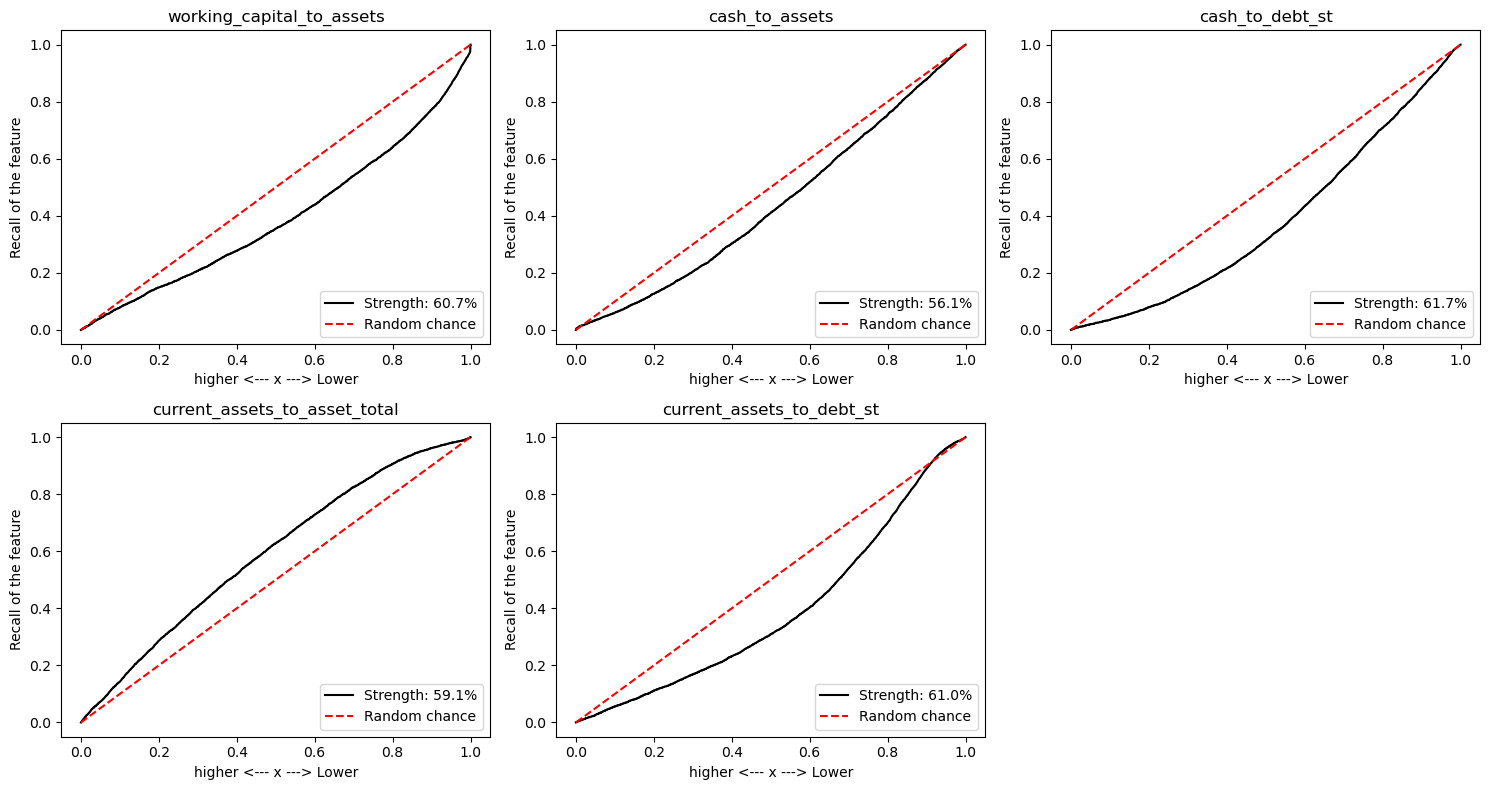

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
2,cash_to_debt_st,0.617024,0.382976,Decreases with feature
4,current_assets_to_debt_st,0.609596,0.390404,Decreases with feature
0,working_capital_to_assets,0.606772,0.393228,Decreases with feature
3,current_assets_to_asset_total,0.591218,0.591218,Increases with feature
1,cash_to_assets,0.560927,0.439073,Decreases with feature


In [12]:
liquidity_and_working_capital = ["working_capital_to_assets", "cash_to_assets", "cash_to_debt_st", "current_assets_to_asset_total", "current_assets_to_debt_st"]
liquidity_and_working_capital_directions = visualize_multiple_features(train_feats, liquidity_and_working_capital, cols=3)
liquidity_and_working_capital_directions

### Solvency

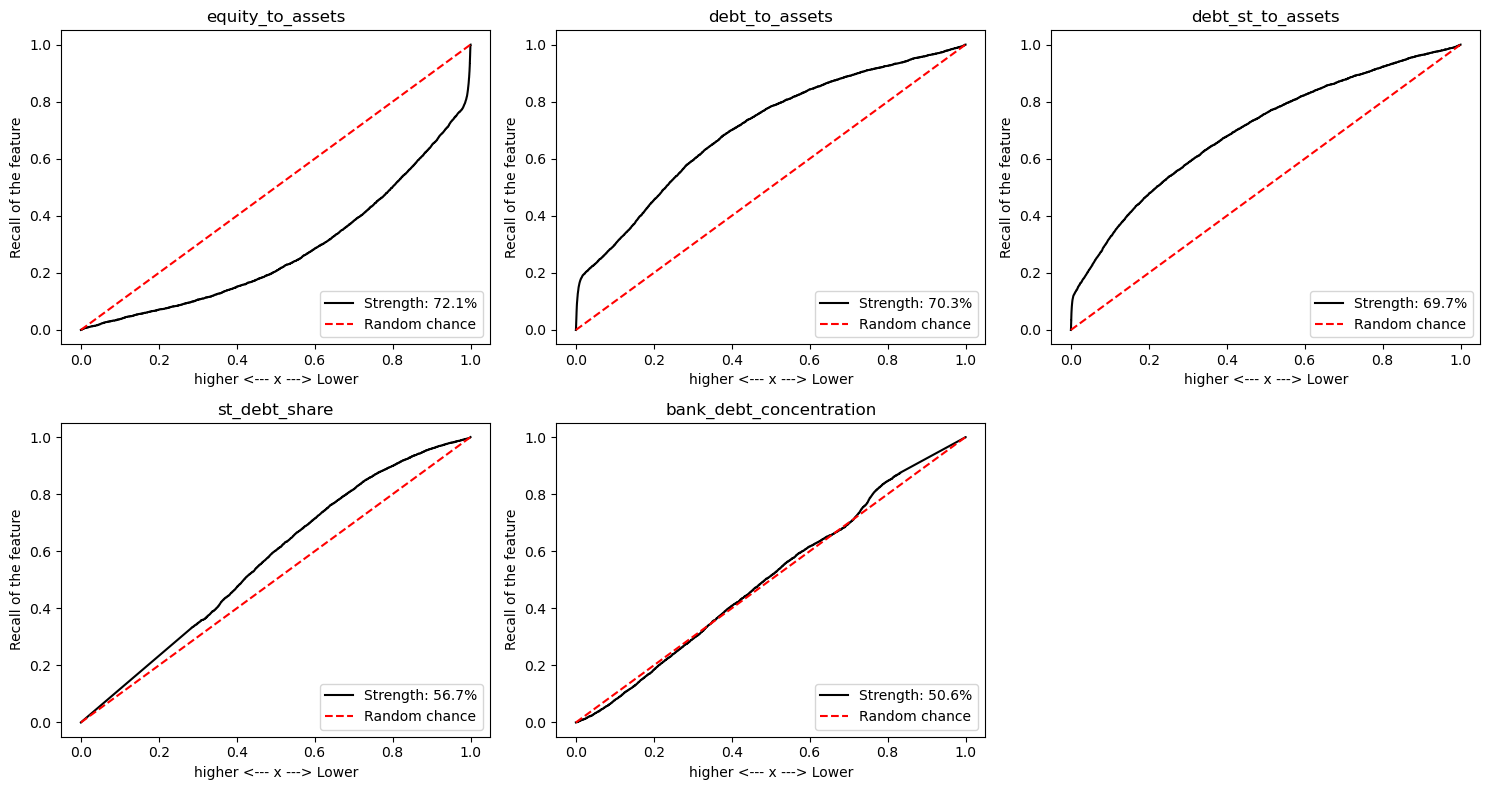

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
0,equity_to_assets,0.721345,0.278655,Decreases with feature
1,debt_to_assets,0.703095,0.703095,Increases with feature
2,debt_st_to_assets,0.696952,0.696952,Increases with feature
3,st_debt_share,0.567174,0.567174,Increases with feature
4,bank_debt_concentration,0.506074,0.506074,Increases with feature


In [13]:
solvency = ["equity_to_assets","debt_to_assets","debt_st_to_assets","st_debt_share","bank_debt_concentration"]
solvency_directions = visualize_multiple_features(train_feats, solvency, cols=3)
solvency_directions

### Debt serving capacity

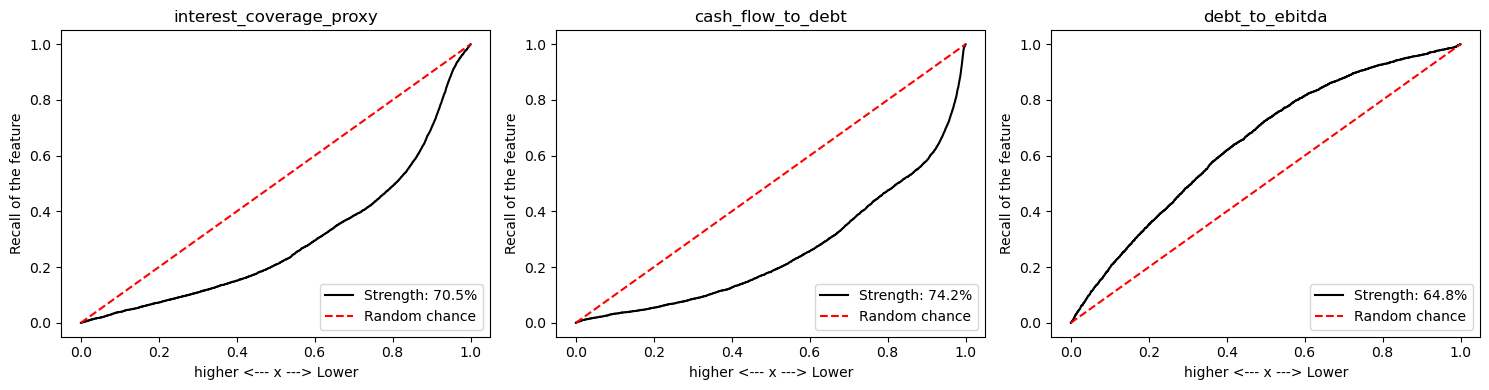

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
1,cash_flow_to_debt,0.741594,0.258406,Decreases with feature
0,interest_coverage_proxy,0.705040,0.294960,Decreases with feature
2,debt_to_ebitda,0.647694,0.647694,Increases with feature


In [14]:
debt_serving_capacity = ["interest_coverage_proxy", "cash_flow_to_debt", "debt_to_ebitda"]
debt_serving_capacity_directions = visualize_multiple_features(train_feats, debt_serving_capacity, cols=3)
debt_serving_capacity_directions

### Cashflow

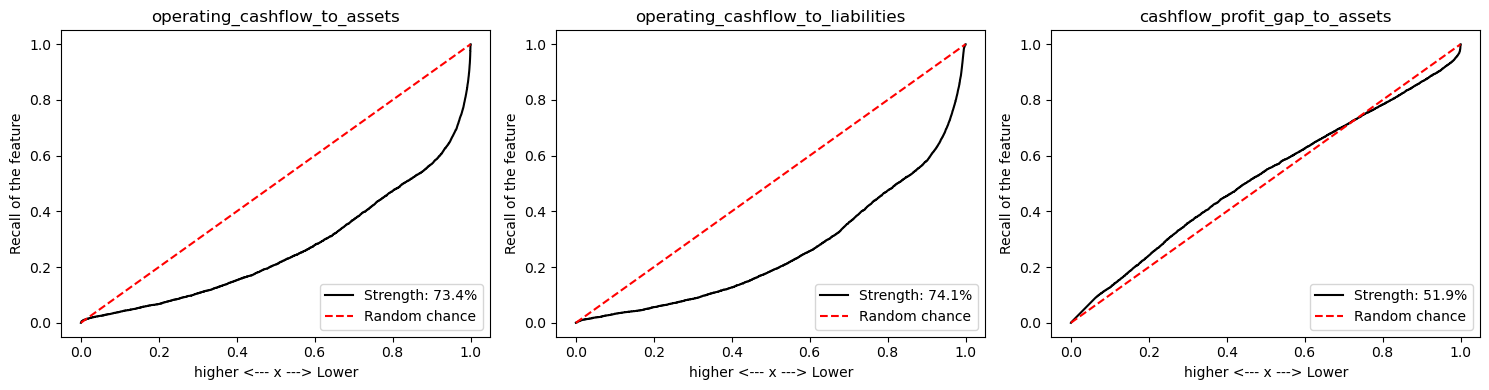

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
1,operating_cashflow_to_liabilities,0.741493,0.258507,Decreases with feature
0,operating_cashflow_to_assets,0.733616,0.266384,Decreases with feature
2,cashflow_profit_gap_to_assets,0.519475,0.519475,Increases with feature


In [15]:
cashflow = ["operating_cashflow_to_assets", "operating_cashflow_to_liabilities", "cashflow_profit_gap_to_assets"]
cashflow_directions = visualize_multiple_features(train_feats, cashflow, cols=3)
cashflow_directions

### Operational efficiency

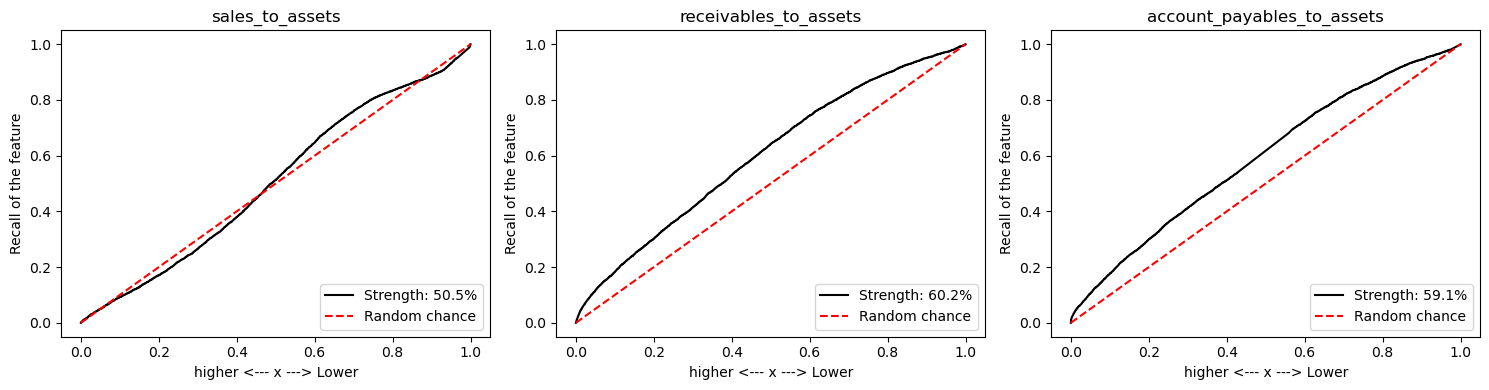

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
1,receivables_to_assets,0.601546,0.601546,Increases with feature
2,account_payables_to_assets,0.591001,0.591001,Increases with feature
0,sales_to_assets,0.504973,0.504973,Increases with feature


In [16]:
operational_efficiency = ["sales_to_assets", "receivables_to_assets", "account_payables_to_assets"]
operational_efficiency_directions = visualize_multiple_features(train_feats, operational_efficiency, cols=3)
operational_efficiency_directions

### Flag cols

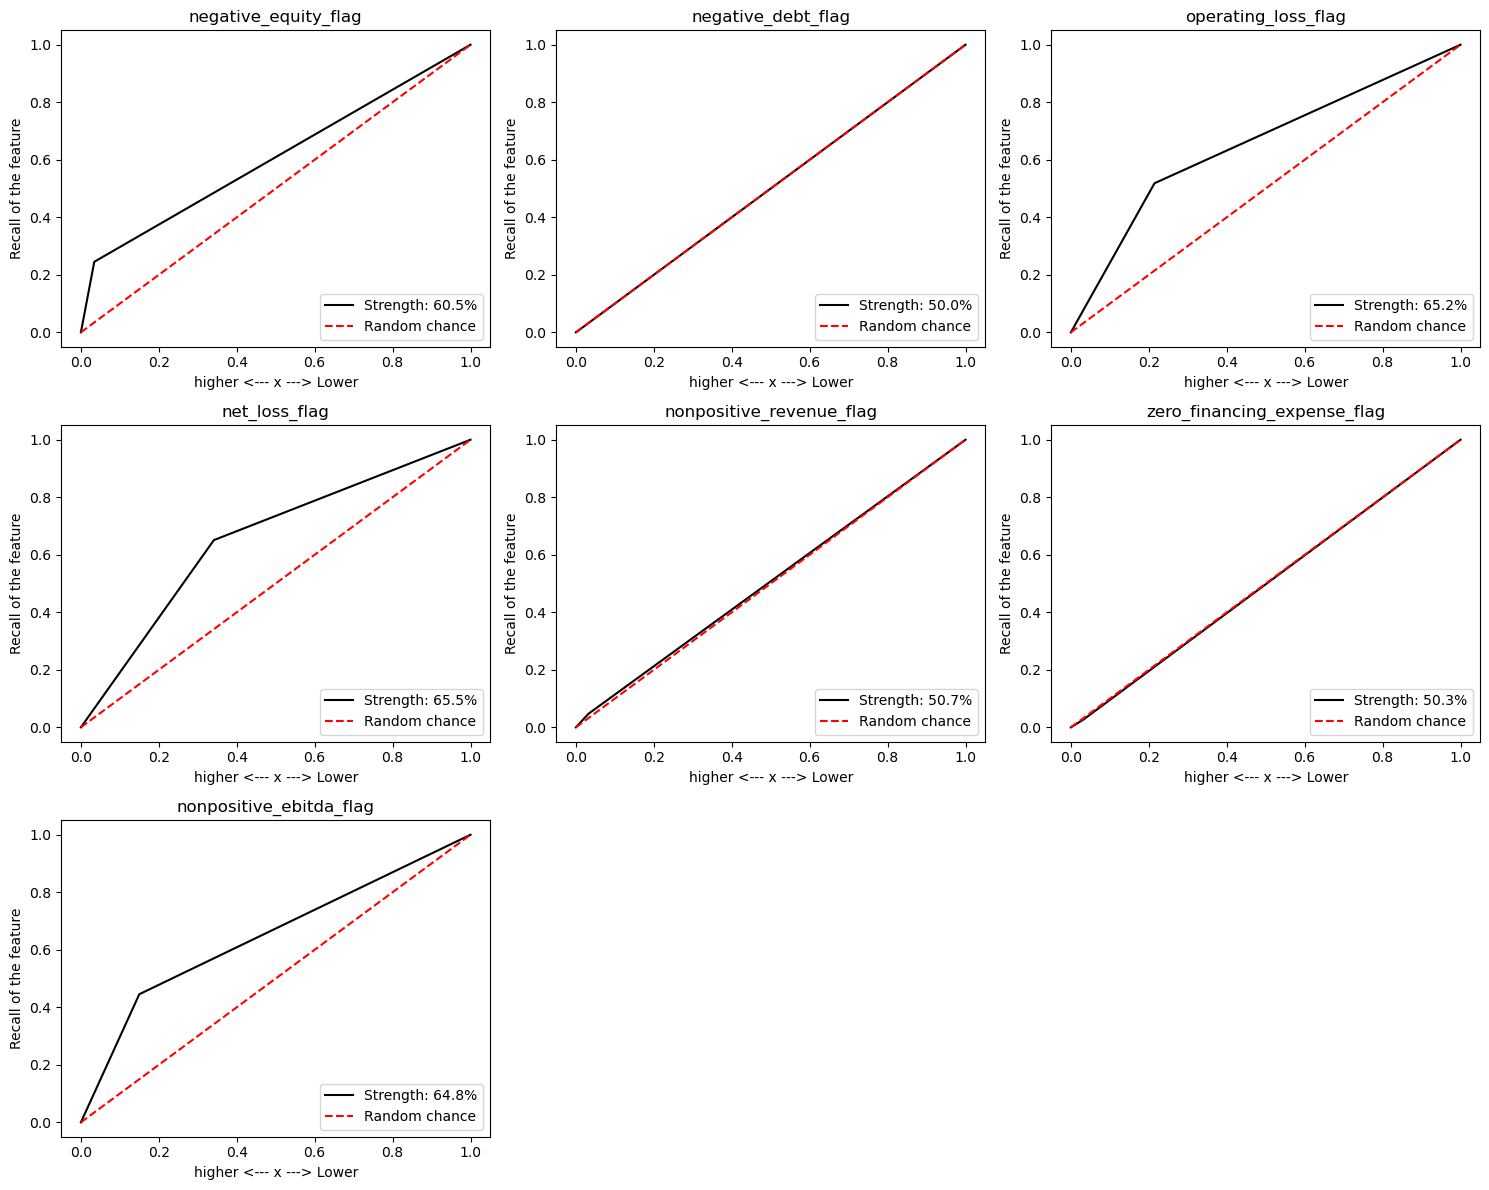

,Feature,Predictive Strength,Raw AUC,Default Risk Direction
3,net_loss_flag,0.654812,0.654812,Increases with feature
2,operating_loss_flag,0.651833,0.651833,Increases with feature
6,nonpositive_ebitda_flag,0.647754,0.647754,Increases with feature
0,negative_equity_flag,0.605444,0.605444,Increases with feature
4,nonpositive_revenue_flag,0.507474,0.507474,Increases with feature
5,zero_financing_expense_flag,0.502565,0.497435,Decreases with feature
1,negative_debt_flag,0.500047,0.499953,Decreases with feature


In [17]:
flag_cols = ["negative_equity_flag", "negative_debt_flag", "operating_loss_flag", "net_loss_flag", "nonpositive_revenue_flag", "zero_financing_expense_flag", "nonpositive_ebitda_flag"]
flag_cols_directions = visualize_multiple_features(train_feats, flag_cols, cols=3)
flag_cols_directions